# 01 — Dados: carga, qualidade e exposição

**Objetivo.** Transformar a base bruta (estipulantes, vidas, sinistros, prêmios) em uma tabela de experiência
auditável: exposição em vidas-ano e capital-ano, óbitos e valores esperados pela tábua, e observados.

**O que este notebook NÃO faz:** precificar. Ele entrega a base que as etapas seguintes (taxa manual,
credibilidade, camada bayesiana) consomem.

**Convenções** (detalhes em `config/base.yaml` e em `src/vgpricing/exposicao.py`):
- segmento cobre de `data_inicio` a `data_fim`, inclusive; `data_fim` vazia = em vigor;
- ano-apólice vai do aniversário até a véspera do seguinte; o último pode ser parcial;
- idade = idade completa no início de cada pedaço de exposição;
- esperado = q_x × exposição (aproximação linear);
- observados = sinistros **avisados** até a data de referência (o IBNR entra na etapa de renovação).

Toda a lógica está no pacote `vgpricing`, coberto por testes (`pytest`). O notebook só orquestra.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing.io import ler_pasta, ler_excel, salvar_pasta
from vgpricing.sintetico import gerar_carteira, injetar_sujeira, tabelas_de_entrada
from vgpricing.validacao import validar
from vgpricing.exposicao import exposicao_detalhada, experiencia

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg = carregar_config("base", RAIZ)
mapas = carregar_config("colunas", RAIZ)
DATA_REF = cfg["data_referencia"]

# Primeira vez nesta máquina: from vgpricing.tabua import baixar_tabua_susep; baixar_tabua_susep()
tabua = obter_tabua(cfg, RAIZ)
print(f"Tábua: {tabua.nome} | fonte: {tabua.fonte}\nsha256: {tabua.sha256}")
if tabua.placeholder:
    print("ATENÇÃO: TÁBUA PLACEHOLDER (ilustrativa, NÃO é BR-EMS). Resultados só testam o pipeline.")
else:
    print("Abas lidas:", tabua.meta["abas"])
    print("Mortalidade mt/sb entre 20 e 80 anos (deve ser > 1):", tabua.meta.get("checagem_mt_maior_que_sb"))
    display(pd.DataFrame(tabua.meta["conciliacao_lx"]).T)
    display((tabua.qx.loc[[20, 30, 40, 50, 60, 70]] * 1000).rename(columns=lambda s: f"q_x por mil ({s})"))

Tábua: BR-EMSmt-2026 | fonte: c:\Users\Arthur\Documents\VS Code\Projetos\vida-grupo-pricing\data\external\tabuas_br_ems.xlsx
sha256: 45a1565083c77042187c1364a58d0f27d90208f140124394d179fb2b8cd70541
Abas lidas: {'M': 'BR-EMSmt-2026-m', 'F': 'BR-EMSmt-2026-f'}
Mortalidade mt/sb entre 20 e 80 anos (deve ser > 1): {'M': 1.293716568596024, 'F': 1.5130687896581514}


c:\Users\Arthur\Documents\VS Code\Projetos\vida-grupo-pricing\src\vgpricing\tabua.py:258: UserWarning: [M] coluna lx: lx defasado em 1 idade em relação ao qx (dif. máx. 8.7% entre 20 e 80 anos). O cálculo usa só o qx, que foi conferido contra o e_x publicado.
  warnings.warn(f"[{s}] coluna lx: {c['diagnostico']} em relação ao qx (dif. máx. {c['max_dif_rel']:.1%} "
c:\Users\Arthur\Documents\VS Code\Projetos\vida-grupo-pricing\src\vgpricing\tabua.py:258: UserWarning: [F] coluna lx: lx defasado em 1 idade em relação ao qx (dif. máx. 9.3% entre 20 e 80 anos). O cálculo usa só o qx, que foi conferido contra o e_x publicado.
  warnings.warn(f"[{s}] coluna lx: {c['diagnostico']} em relação ao qx (dif. máx. {c['max_dif_rel']:.1%} "


,disponivel,faixa,max_dif_rel,max_dif_rel_lx_defasado_1_idade,diagnostico
M,True,"[20, 80]",0.0873,0.0007,lx defasado em 1 idade
F,True,"[20, 80]",0.0927,0.0019,lx defasado em 1 idade


,q_x por mil (M),q_x por mil (F)
idade,,
20,1.0324,0.3513
30,1.1480,0.5150
40,1.5071,0.8954
50,3.3459,2.0481
60,8.2498,5.2297
70,20.5481,13.7277


## 1. Fonte dos dados

`FONTE = "sintetico"` gera a carteira de teste. Para dados reais, troque para `"excel"` (template em
`templates/`) ou `"pasta"` (parquet/CSV extraídos do banco) e ajuste só `config/colunas.yaml`.

In [2]:
FONTE = "sintetico"   # "sintetico" | "excel" | "pasta"

if FONTE == "sintetico":
    cfg_s = carregar_config("sintetico", RAIZ)
    carteira = gerar_carteira(cfg_s, tabua)
    suja, verdade_sujeira = injetar_sujeira(carteira, cfg_s)
    salvar_pasta(tabelas_de_entrada(suja), RAIZ / "data/synthetic")
    # relê pelo mesmo caminho que um dado real usaria
    dados, problemas_leitura = ler_pasta(RAIZ / "data/synthetic", mapas, "parquet")
elif FONTE == "excel":
    dados, problemas_leitura = ler_excel(RAIZ / "data/raw/entrada.xlsx", mapas)
else:
    dados, problemas_leitura = ler_pasta(RAIZ / "data/raw", mapas, "parquet")

pd.DataFrame({k: [len(v)] for k, v in dados.items()}, index=["linhas"])

,estipulantes,vidas,sinistros,premios
linhas,250,743623,1904,1249


In [3]:
print("Problemas de conversão de tipo na leitura:", len(problemas_leitura))
problemas_leitura.head()

Problemas de conversão de tipo na leitura: 0


,tabela,coluna,id_linha,valor_original,tipo_esperado


## 2. Qualidade de dados

Cada regra tem código, severidade e ação (`excluir` ou `sinalizar`). Regras rodam em ordem; um registro
excluído não é reavaliado pelas regras seguintes. Nada é corrigido automaticamente: o log abaixo é o que
vai para o time de cadastro e para a auditoria.

In [4]:
res = validar(dados, cfg)
res.resumo()

c:\Users\Arthur\Documents\VS Code\Projetos\vida-grupo-pricing\src\vgpricing\validacao.py:59: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(self.linhas, ignore_index=True)


,codigo,tabela,descricao,acao,severidade,registros
0,S01,sinistros,sinistro duplicado,excluir,alta,37
1,S02,sinistros,vida não encontrada na base de vidas (mantido ...,sinalizar,alta,19
2,S03,sinistros,ocorrência fora de período de cobertura na bas...,sinalizar,alta,12
3,S04,sinistros,aviso anterior à ocorrência,sinalizar,media,19
4,S06,sinistros,sinistro negado: fora da experiência,excluir,info,62
5,V01,vidas,linha duplicada,excluir,media,3700
6,V03,vidas,nascimento ausente ou posterior ao início,excluir,alta,740
7,V04,vidas,idade de entrada impossível,excluir,alta,1480
8,V05,vidas,sexo ausente/inválido (usa média M/F da tábua),sinalizar,media,3700
9,V06,vidas,capital ausente ou não positivo,excluir,alta,740


**Prova de detecção (só no sintético).** O gerador registrou exatamente quais linhas sujou e qual regra
deveria pegá-las. A tabela compara.

In [5]:
if FONTE == "sintetico":
    ex = res.excecoes
    linhas = []
    for (tab, cod), g in verdade_sujeira.groupby(["tabela", "codigo"]):
        col = "id_linha" if tab == "vidas" else "id_sinistro"
        marc = set(ex.loc[ex["codigo"] == cod, col].astype(str)); inj = set(g["chave"].astype(str))
        linhas.append({"regra": cod, "injetados": len(inj), "detectados": len(marc & inj),
                       "nao_detectados": len(inj - marc), "falsos_alarmes": len(marc - inj)})
    display(pd.DataFrame(linhas))

,regra,injetados,detectados,nao_detectados,falsos_alarmes
0,S01,37,37,0,0
1,S02,19,19,0,0
2,S04,19,19,0,0
3,V01,3700,3700,0,0
4,V03,740,740,0,0
5,V04,1480,1480,0,0
6,V05,3700,3700,0,0
7,V06,740,740,0,0
8,V07,740,740,0,0


Sinistros sinalizados com `S03` (ocorrência fora de cobertura) que não foram injetados são consequência
esperada: a vida tinha o segmento do óbito sujo e ele foi excluído. Na base real, isso indica que o sinistro
precisa de investigação de cadastro antes de entrar no cálculo de renovação.

In [6]:
ex = res.excecoes
ex[ex["codigo"] == "S03"].head()

,codigo,tabela,descricao,severidade,acao,id_linha,id_sinistro,id_estipulante,detalhe
13633,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,70,SIN0000072,EST0006,
13634,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,465,SIN0000488,EST0063,
13635,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,569,SIN0000596,EST0067,
13636,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,778,SIN0000817,EST0084,
13637,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,817,SIN0000860,EST0090,


## 3. Exposição e experiência

A tabela de experiência é estipulante × ano-apólice. `n_efetivo` é o número efetivo de óbitos esperados
quando o A/E é ponderado por capital: (Σ C·q·t)² / Σ C²·q·t. Ele cai quando o capital é concentrado em
poucas vidas, e é ele (não o número de vidas) que deve dar o peso de credibilidade na renovação.

In [7]:
det = exposicao_detalhada(res.dados["vidas"], res.dados["estipulantes"], tabua, DATA_REF,
                          cfg["exposicao"]["dias_por_ano"])
xp = experiencia(det, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF)
xp.head()

,id_estipulante,ano_apolice,vidas_ano,capital_ano,obitos_esperados,valor_esperado,soma_c2q,obitos_observados,valor_observado,n_efetivo,ae_obitos,ae_valor
0,EST0000,1,202.8446,"35,505,774.1273",0.3101,"52,592.7249","15,910,689,500.6156",0.0000,0.0000,0.1738,0.0000,0.0000
1,EST0000,2,212.8871,"38,281,870.4997",0.3260,"56,700.7423","16,725,525,979.5933",0.0000,0.0000,0.1922,0.0000,0.0000
2,EST0000,3,227.5264,"41,926,029.2950",0.3642,"64,136.3073","19,452,571,647.6676",0.0000,0.0000,0.2115,0.0000,0.0000
3,EST0000,4,232.1095,"43,128,707.1869",0.3945,"71,360.3979","21,048,055,801.8939",0.0000,0.0000,0.2419,0.0000,0.0000
4,EST0000,5,140.0657,"26,462,848.7337",0.2618,"48,824.2543","14,382,669,853.7543",0.0000,0.0000,0.1657,0.0000,0.0000


In [8]:
tot = xp[["vidas_ano", "capital_ano", "obitos_esperados", "obitos_observados",
           "valor_esperado", "valor_observado"]].sum()
resumo = pd.Series({
    "estipulantes": xp["id_estipulante"].nunique(),
    "vidas-ano": tot["vidas_ano"],
    "capital-ano (R$ bi)": tot["capital_ano"] / 1e9,
    "óbitos esperados": tot["obitos_esperados"],
    "óbitos observados (avisados)": tot["obitos_observados"],
    "A/E óbitos": tot["obitos_observados"] / tot["obitos_esperados"],
    "A/E valor": tot["valor_observado"] / tot["valor_esperado"],
})
resumo.to_frame("carteira")

,carteira
estipulantes,250.0000
vidas-ano,"1,068,315.3730"
capital-ano (R$ bi),79.5823
óbitos esperados,"1,881.3186"
óbitos observados (avisados),"1,805.0000"
A/E óbitos,0.9594
A/E valor,0.9268


### A/E por setor, com intervalo exato de Poisson (95%)

Intervalo de Garwood para o número de óbitos, dividido pelos esperados. Serve de primeira leitura antes do
GLM da Etapa 2, que vai separar setor de idade, sexo e capital.

In [9]:
det_s = det.merge(res.dados["estipulantes"][["id_estipulante", "setor"]], on="id_estipulante")
xs = experiencia(det_s, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF, por=("setor",))
O, E = xs["obitos_observados"], xs["obitos_esperados"]
xs["ae_inf"] = np.where(O > 0, chi2.ppf(0.025, 2 * O) / 2, 0) / E
xs["ae_sup"] = chi2.ppf(0.975, 2 * (O + 1)) / 2 / E
xs = xs.sort_values("ae_obitos")
if FONTE == "sintetico":
    xs = xs.merge(pd.DataFrame([{"setor": s, "fator_hipotese": v["fator_mortalidade"]}
                                for s, v in cfg_s["setores"].items()]), on="setor")
xs[[c for c in ["setor", "vidas_ano", "obitos_esperados", "obitos_observados", "ae_obitos",
                "ae_inf", "ae_sup", "fator_hipotese"] if c in xs]]

,setor,vidas_ano,obitos_esperados,obitos_observados,ae_obitos,ae_inf,ae_sup,fator_hipotese
0,financeiro,"201,532.5777",290.9180,210,0.7219,0.6275,0.8264,0.8500
1,adm_publica,"54,781.2841",151.6991,137,0.9031,0.7582,1.0676,0.9500
2,comercio,"147,777.8617",183.0576,168,0.9177,0.7842,1.0675,1.0500
3,servicos,"288,014.2012",451.0682,423,0.9378,0.8505,1.0315,1.0000
4,industria,"218,502.3901",434.9330,415,0.9542,0.8646,1.0505,1.1500
5,construcao,"82,277.9877",167.9626,200,1.1907,1.0314,1.3677,1.3500
6,transporte,"75,429.0705",201.6803,252,1.2495,1.1000,1.4137,1.3000


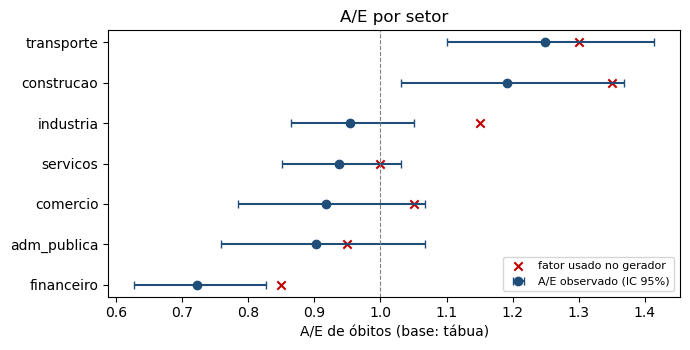

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(xs))
ax.errorbar(xs["ae_obitos"], y, xerr=[xs["ae_obitos"] - xs["ae_inf"], xs["ae_sup"] - xs["ae_obitos"]],
            fmt="o", color="#1f4e79", capsize=3, label="A/E observado (IC 95%)")
if "fator_hipotese" in xs:
    ax.scatter(xs["fator_hipotese"], y, marker="x", color="#c00000", label="fator usado no gerador")
ax.axvline(1, color="grey", lw=0.8, ls="--")
ax.set_yticks(y, xs["setor"]); ax.set_xlabel("A/E de óbitos (base: tábua)")
ax.set_title("A/E por setor" + (" — TÁBUA PLACEHOLDER" if tabua.placeholder else ""))
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

O A/E por setor tende a ficar abaixo do fator usado no gerador por dois motivos: os observados ainda não
incluem o IBNR (ajuste da Etapa 3) e os sinistros negados ficam, corretamente, fora. Além disso, cada setor
carrega o efeito aleatório dos seus estipulantes, que só se anula em média: setores com poucos grupos
grandes podem cair acima ou abaixo do fator. Separar esses efeitos é o papel do GLM (Etapa 2).

### Por que o número efetivo importa

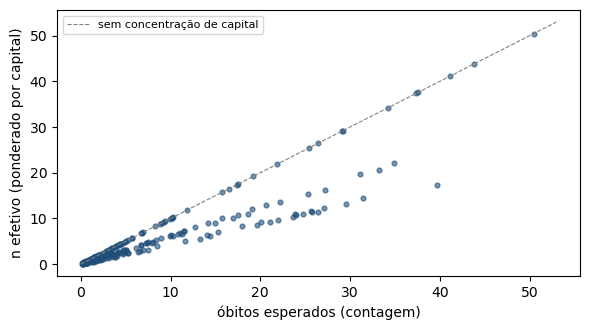

count   250.0000
mean      0.7270
std       0.2346
min       0.3455
25%       0.5234
50%       0.6359
75%       1.0000
max       1.0000
Name: razao_n_ef_por_esperados, dtype: float64

In [11]:
grp = xp.groupby("id_estipulante")[["vidas_ano", "obitos_esperados", "valor_esperado", "soma_c2q"]].sum()
grp["n_efetivo"] = grp["valor_esperado"] ** 2 / grp["soma_c2q"]
grp["razao_n_ef_por_esperados"] = grp["n_efetivo"] / grp["obitos_esperados"]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(grp["obitos_esperados"], grp["n_efetivo"], s=12, alpha=0.6, color="#1f4e79")
lim = grp["obitos_esperados"].max() * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=0.8, label="sem concentração de capital")
ax.set_xlabel("óbitos esperados (contagem)"); ax.set_ylabel("n efetivo (ponderado por capital)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
grp["razao_n_ef_por_esperados"].describe()

Grupos com capital uniforme ficam na diagonal. Em grupos com múltiplo salarial ou capital escalonado,
o n efetivo é bem menor que a contagem de óbitos esperados: usar a contagem daria credibilidade demais a
grupos cuja sinistralidade em R$ depende de poucas vidas de capital alto.

## 4. Conciliação de prêmio

In [12]:
p = res.dados.get("premios")
if p is not None and "dif_rel" in p:
    print("Períodos com divergência acima da tolerância:", int((p["dif_rel"].abs() > cfg["validacao"]["tolerancia_conciliacao_premio"]).sum()),
          "de", len(p))
    display(p["dif_rel"].describe())

Períodos com divergência acima da tolerância: 0 de 1249


count   0.0000
mean       NaN
std        NaN
min        NaN
25%        NaN
50%        NaN
75%        NaN
max        NaN
Name: dif_rel, dtype: float64

As divergências vêm dos registros excluídos na validação (o prêmio foi faturado sobre a base suja).
Afastados não geram divergência porque continuam faturados e entram na conciliação.

## 5. Saídas desta etapa

Gravadas em `data/synthetic/` (ou `data/processed/` no uso real): base limpa, log de exceções e tabela de
experiência. São a entrada da Etapa 2.

In [13]:
saida = RAIZ / "data" / ("synthetic" if FONTE == "sintetico" else "processed")
saida.mkdir(parents=True, exist_ok=True)
res.excecoes.to_csv(saida / "log_excecoes.csv", index=False)
xp.to_parquet(saida / "experiencia_estipulante_ano.parquet", index=False)
det.to_parquet(saida / "exposicao_detalhada.parquet", index=False)
salvar_pasta(res.dados, saida / "limpo")
if FONTE == "sintetico":
    carteira["verdade_estipulantes"].to_parquet(saida / "verdade_estipulantes.parquet", index=False)
    carteira["verdade_ibnr"].to_parquet(saida / "verdade_ibnr.parquet", index=False)
sorted(x.name for x in saida.rglob("*") if x.is_file())

['.gitkeep',
 'estipulantes.parquet',
 'estipulantes.parquet',
 'experiencia_estipulante_ano.parquet',
 'exposicao_detalhada.parquet',
 'log_excecoes.csv',
 'premios.parquet',
 'premios.parquet',
 'sinistros.parquet',
 'sinistros.parquet',
 'verdade_estipulantes.parquet',
 'verdade_ibnr.parquet',
 'vidas.parquet',
 'vidas.parquet']

## Limitações desta etapa
- Com a tábua placeholder, os **níveis** de A/E não têm significado de mercado; a mecânica sim.
- Esperado linear (q·t) superestima levemente em pedaços longos e idades altas; o efeito é desprezível
  para q_x de idades ativas.
- Sexo ausente usa a média M/F da tábua, sinalizado no log (V05).
- Observados ainda sem IBNR; o A/E de anos recentes está subestimado até o ajuste da Etapa 3.